# 04 · Sentiment and polarity

* **VADER** is built for social media text and handles caps, punctuation ("!!!"), negation and emoji. The compound score runs from −1 to +1, labelled positive / neutral / negative at ±0.05 (the standard VADER cut-offs).
* **TextBlob** is the comparison: polarity (−1 to +1) and subjectivity (0 to 1), with the same ±0.05 labels.
* **VADER + sports words**: standard VADER doesn't know much college-football slang (see section 1). A second VADER score adds a small, documented list of sports words. **This is the main score from notebook 05 on**, chosen because it matched the hand labels best (section 4). Standard VADER and TextBlob are kept for comparison.
* **Hand-labeled check**: about 50 comments labeled by hand in `data/hand_labels.csv` give each tool's accuracy on this kind of text.
* **Expansion-topic flag** for comparing sentiment on the expansion topic.

In [1]:
import sys
import re
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))
import config

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 110)
FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

CREATOR_NAMES = {"pate": "Josh Pate", "crain_cone": "Crain & Cone"}
CREATOR_COLORS = {"Josh Pate": "#1f5fa8", "Crain & Cone": "#d9822b"}
PERIOD_ORDER = ["before", "announcement", "after"]

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

In [2]:
df = pd.read_csv(config.DATA_DIR / "comments_clean.csv", keep_default_na=False,
                 parse_dates=["published_utc", "updated_utc", "video_published_utc"])
df["country"] = df["country"].replace("", np.nan)
df["creator_name"] = df["creator"].map(CREATOR_NAMES)
df.shape

(9456, 29)

## 1. How standard VADER handles sports slang

Word frequency in the corpus next to VADER's built-in score for the word. Many common negative sports words aren't in VADER's word list at all, so it scores them 0. Some score the wrong way: "L" (a loss) is positive, and "joke" ("these rankings are a joke") is positive.

In [3]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob

vader = SentimentIntensityAnalyzer()

SLANG = ["trash", "garbage", "overrated", "delusional", "clown", "robbed", "cope", "mid", "cooked", "bum",
         "glazing", "fraud", "rigged", "joke", "L", "W", "goated", "underrated", "respect"]

def count_word(word):
    pattern = rf"(?<!\w){re.escape(word)}(?!\w)"
    return int(df["text_body"].str.contains(pattern, case=(word in ("L", "W")), regex=True).sum())

slang_table = pd.DataFrame({
    "comments_using_it": [count_word(w) for w in SLANG],
    "vader_word_score": [vader.lexicon.get(w.lower(), 0.0) for w in SLANG],
    "textblob_polarity": [TextBlob(w).sentiment.polarity for w in SLANG],
}, index=SLANG).sort_values("comments_using_it", ascending=False)
slang_table

,comments_using_it,vader_word_score,textblob_polarity
joke,114,1.2,0.0
respect,69,2.1,0.0
overrated,68,0.0,0.0
trash,54,0.0,0.0
garbage,41,0.0,0.0
mid,38,0.0,0.0
robbed,31,0.0,0.0
delusional,24,0.0,0.0
L,22,2.0,0.0
cope,21,0.0,0.0


### Sports word list

Scores use VADER's scale (−4 to +4; most of its everyday negative words sit between −1.5 and −2.5). The values are the project's own judgement of how the words are used in these comments, and they're checked against the hand labels in section 4. The list lives in `config.py` (`SPORTS_LEXICON`) so that every notebook uses the same one.

In [4]:
SPORTS_LEXICON = config.SPORTS_LEXICON
print(pd.Series(SPORTS_LEXICON).rename("VADER score").to_string())

vader_sports = SentimentIntensityAnalyzer()
vader_sports.lexicon.update(SPORTS_LEXICON)

for s in ["These rankings are a joke", "Huge L for the committee", "Bama is overrated trash", "W video JP"]:
    print(f"{s:30}  VADER {vader.polarity_scores(s)['compound']:+.2f}   "
          f"VADER+sports {vader_sports.polarity_scores(s)['compound']:+.2f}")

trash        -2.0
garbage      -2.0
overrated    -1.5
delusional   -1.8
clown        -1.8
clowns       -1.8
robbed       -2.0
cope         -1.2
coping       -1.2
mid          -1.0
cooked       -1.5
washed       -1.5
bum          -1.8
bums         -1.8
glazing      -1.0
glaze        -1.0
esecn        -1.5
frauds       -2.5
l            -1.5
joke         -1.5
w             1.5
goated        2.0
underrated    1.0
These rankings are a joke       VADER +0.30   VADER+sports -0.36
Huge L for the committee        VADER +0.72   VADER+sports -0.23
Bama is overrated trash         VADER +0.00   VADER+sports -0.67
W video JP                      VADER +0.37   VADER+sports +0.70


## 2. Score every comment

Scores use `text_body` (the comment without the leading reply handle).

In [5]:
def label(score, cut=0.05):
    return "positive" if score >= cut else ("negative" if score <= -cut else "neutral")

df["vader_compound"] = df["text_body"].apply(lambda t: vader.polarity_scores(t)["compound"])
df["vader_sports_compound"] = df["text_body"].apply(lambda t: vader_sports.polarity_scores(t)["compound"])
blobs = df["text_body"].apply(lambda t: TextBlob(t).sentiment)
df["tb_polarity"] = blobs.apply(lambda s: s.polarity)
df["tb_subjectivity"] = blobs.apply(lambda s: s.subjectivity)

for col in ["vader", "vader_sports"]:
    df[f"{col}_label"] = df[f"{col}_compound"].apply(label)
df["tb_label"] = df["tb_polarity"].apply(label)

dist = pd.DataFrame({c: df[f"{c}_label"].value_counts(normalize=True) for c in ["vader", "vader_sports", "tb"]})
(dist.reindex(["positive", "neutral", "negative"]) * 100).round(1)

,vader,vader_sports,tb
positive,51.0,49.8,43.6
neutral,19.3,18.7,34.9
negative,29.7,31.5,21.5


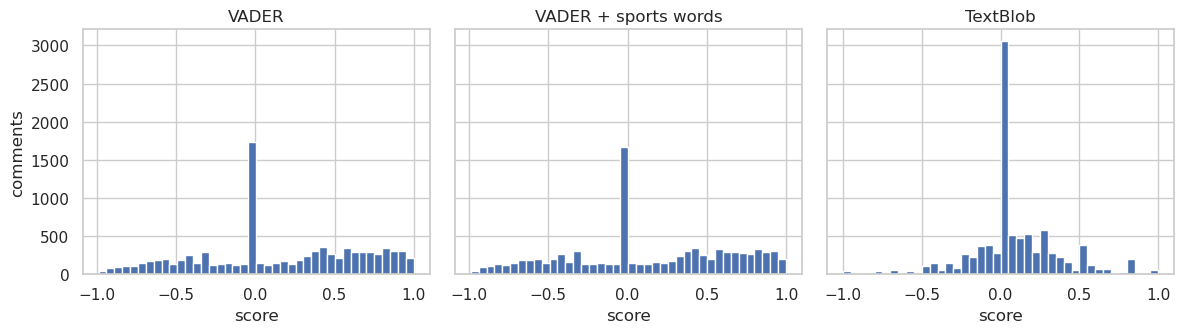

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
for ax, (col, title) in zip(axes, [("vader_compound", "VADER"), ("vader_sports_compound", "VADER + sports words"),
                                   ("tb_polarity", "TextBlob")]):
    ax.hist(df[col], bins=40, color="#4c72b0")
    ax.set(title=title, xlabel="score")
axes[0].set_ylabel("comments")
save(fig, "04_score_distributions.png")

## 3. VADER vs TextBlob

In [7]:
print("correlation of scores:")
print(df[["vader_compound", "vader_sports_compound", "tb_polarity"]].corr().round(2).to_string())
print(f"\nVADER and TextBlob give the same label on {(df['vader_label'] == df['tb_label']).mean():.0%} of comments")
pd.crosstab(df["vader_label"], df["tb_label"], margins=True)

correlation of scores:
                       vader_compound  vader_sports_compound  tb_polarity
vader_compound                   1.00                   0.98         0.46
vader_sports_compound            0.98                   1.00         0.46
tb_polarity                      0.46                   0.46         1.00

VADER and TextBlob give the same label on 59% of comments


tb_label,negative,neutral,positive,All
vader_label,,,,
negative,1197,920,689,2806
neutral,253,1261,314,1828
positive,581,1122,3119,4822
All,2031,3303,4122,9456


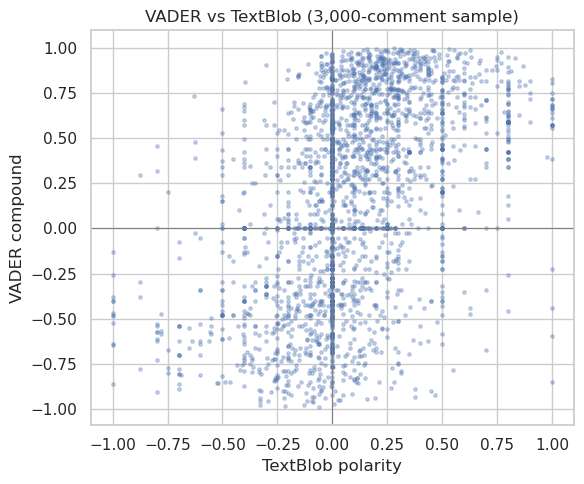

In [8]:
fig, ax = plt.subplots(figsize=(6, 5))
sample = df.sample(min(3000, len(df)), random_state=0)
ax.scatter(sample["tb_polarity"], sample["vader_compound"], s=6, alpha=0.3, color="#4c72b0")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(0, color="grey", lw=0.8)
ax.set(xlabel="TextBlob polarity", ylabel="VADER compound", title="VADER vs TextBlob (3,000-comment sample)")
save(fig, "04_vader_vs_textblob_scatter.png")

In [9]:
print(f"TextBlob scores exactly 0 for {(df['tb_polarity'] == 0).mean():.0%} of comments; "
      f"VADER for {(df['vader_compound'] == 0).mean():.0%}")
print("\nexamples where the two disagree most:")
df.assign(gap=(df["vader_compound"] - df["tb_polarity"]).abs()).nlargest(8, "gap")[
    ["vader_compound", "tb_polarity", "text_body"]]

TextBlob scores exactly 0 for 28% of comments; VADER for 18%

examples where the two disagree most:


,vader_compound,tb_polarity,text_body
1466,-0.8520,1.0,no. seen them not play their best. They will beat texas to death
1879,-0.6776,1.0,No not the best
5988,-0.5975,1.0,"went to OT vs Michigan ON PURPOSE because IU has one of, if not the best defenses in CFB"
7324,-0.9501,0.6,Always use money to bless people showing God you don't praise money over him & people & children who needs...
2207,0.5393,-1.0,This is a horrible cfb bracket 😆😆Miami not beating Georgia with that defense
4417,0.5106,-1.0,Bama over BYU and UCLA is insane \nBut a respect for Kentucky ranking
112,-0.7988,0.7,A and m scares me we do no play good on the road and we struggle against mobile qbs
1550,-0.5984,0.9,Incredible rage bait here.


## 4. Hand-labeled accuracy check

`data/hand_labels.csv` holds a fixed sample of 50 comments: 30 that contain slang or emoji from the lists above, and 20 picked at random. The `label` column is filled in by hand: **positive**, **neutral** or **negative**, for the commenter's overall tone. The sheet deliberately shows no tool scores, so they can't influence the labels.

The cell below creates the sheet the first time and **never overwrites it**. Once the labels are filled in, rerun this section.

In [10]:
LABEL_FILE = config.DATA_DIR / "hand_labels.csv"

if not LABEL_FILE.exists():
    slang_pattern = "|".join(rf"(?<!\w){re.escape(w)}(?!\w)" for w in SLANG if w not in ("L", "W"))
    has_slang = (df["text_body"].str.contains(slang_pattern, case=False, regex=True)
                 | df["text_body"].str.contains(r"(?<!\w)[LW](?!\w)|💀|🤡|😂", regex=True))
    readable = df["n_words"].between(3, 60)
    slang_pick = df[has_slang & readable].groupby("creator").sample(n=15, random_state=42)
    rest = df[~df.index.isin(slang_pick.index) & readable]
    random_pick = rest.groupby("creator").sample(n=10, random_state=42)
    sheet = (pd.concat([slang_pick.assign(sample="slang"), random_pick.assign(sample="random")])
             .sample(frac=1, random_state=1)[["comment_id", "sample", "text_body"]]
             .assign(label="", note=""))
    sheet.to_csv(LABEL_FILE, index=False)
    print(f"created {LABEL_FILE.relative_to(ROOT)} with {len(sheet)} comments to label")

labels = pd.read_csv(LABEL_FILE, keep_default_na=False)
labels["label"] = labels["label"].str.strip().str.lower()
done = labels["label"].isin(["positive", "neutral", "negative"])
print(f"{done.sum()} of {len(labels)} comments labeled")

50 of 50 comments labeled


In [11]:
from sklearn.metrics import accuracy_score, f1_score

if done.sum() < 40:
    print("Fill in the `label` column of data/hand_labels.csv (positive / neutral / negative), then rerun this section.")
else:
    lab = labels[done].merge(df[["comment_id", "vader_label", "vader_sports_label", "tb_label"]], on="comment_id")
    results = pd.DataFrame({
        name: {"accuracy": accuracy_score(lab["label"], lab[col]),
               "macro_F1": f1_score(lab["label"], lab[col], average="macro"),
               "accuracy_on_slang_sample": accuracy_score(lab.loc[lab["sample"] == "slang", "label"],
                                                          lab.loc[lab["sample"] == "slang", col])}
        for name, col in [("VADER", "vader_label"), ("VADER + sports", "vader_sports_label"), ("TextBlob", "tb_label")]
    }).T.round(2)
    display(results)
    for name, col in [("VADER", "vader_label"), ("VADER + sports", "vader_sports_label"), ("TextBlob", "tb_label")]:
        print(name)
        display(pd.crosstab(lab["label"], lab[col], rownames=["hand label"], colnames=["tool"]))
    print("VADER mistakes:")
    display(lab[lab["label"] != lab["vader_label"]][["label", "vader_label", "vader_sports_label", "text_body"]])
    laugh = lab["text_body"].str.contains("😂|🤣")
    print(f"Comments with 😂/🤣: {laugh.sum()}; VADER matches the hand label on {(lab.loc[laugh, 'vader_label'] == lab.loc[laugh, 'label']).sum()} of them")
    print(f"Calling every comment negative would match {(lab['label'] == 'negative').mean():.0%} of the hand labels")

,accuracy,macro_F1,accuracy_on_slang_sample
VADER,0.34,0.29,0.17
VADER + sports,0.52,0.40,0.47
TextBlob,0.34,0.27,0.37


VADER


tool,negative,neutral,positive
hand label,,,
negative,13,3,20
neutral,3,2,5
positive,2,0,2


VADER + sports


tool,negative,neutral,positive
hand label,,,
negative,21,2,13
neutral,3,2,5
positive,1,0,3


TextBlob


tool,negative,neutral,positive
hand label,,,
negative,14,12,10
neutral,1,1,8
positive,0,2,2


VADER mistakes:


,label,vader_label,vader_sports_label,text_body
0,neutral,positive,positive,I'm reading these comments sitting cozy in the great state of ALABAMA genuinely LMFAO 😂😂😂\n\nROLL TIDE ROLL!
1,neutral,positive,positive,Lol and cops dont make rules they just enforce them.
4,negative,positive,positive,"Yeah, did you pick up all that acumen for football in junior high or high school? Where I guarantee you? Y..."
7,negative,positive,negative,Texas at 7? That's the biggest joke on this ranking
9,neutral,negative,negative,This is the battle of which pass rush can make the qb make more mistakes! Which qb can protect the ball ?
11,negative,positive,positive,Rolltide!! f it at this point 😂
12,negative,positive,positive,😂😂😂😂😂 you got it bro
13,negative,positive,positive,"I am a Tiger fan but Texas will win, with help from the refs."
14,positive,negative,positive,"Oregon has inproved immensely since firing Drew at OC, our defense has also been lights out after adjustme..."
17,negative,positive,negative,"No, but there should be. Their schedule is an absolute joke."


Comments with 😂/🤣: 16; VADER matches the hand label on 2 of them
Calling every comment negative would match 72% of the hand labels


### Where the tools fail: direct vs indirect negativity

Every comment hand-labeled negative was also given a **type** in the `note` column, describing *how* the negativity is expressed:

* **Direct**: *criticism* (a calm or blunt complaint about a team, the committee or the format) and *insulting* (a putdown of a person or team).
* **Indirect**: *sarcasm*, *teasing*, *gloating* and *defeatist* (resigned, "this sucks", "and yet we all still watch"). Here the words on the surface don't carry the meaning.

A few neutral and positive comments also have notes (e.g. *factual*, *laughing*). Comments containing laughing emoji (😂 🤣) are counted separately, because VADER reads them as joy whatever the writer means.

The groups are small (2 to 16 comments), so the numbers show the *kind* of error rather than a precise rate.

In [12]:
if done.sum() >= 40:
    TYPE_NAMES = {"sarcastic": "sarcasm"}             # spelling variants used in the notes
    DIRECT, INDIRECT = ["criticism", "insulting"], ["sarcasm", "teasing", "gloating", "defeatist"]
    TOOLS = [("VADER", "vader_label"), ("VADER + sports", "vader_sports_label"), ("TextBlob", "tb_label")]

    lab["type"] = lab["note"].str.strip().str.lower().replace(TYPE_NAMES)
    lab["laughing emoji"] = lab["text_body"].str.contains("😂|🤣")
    neg = lab[lab["label"] == "negative"].copy()
    neg["style"] = np.select([neg["type"].isin(DIRECT), neg["type"].isin(INDIRECT)], ["direct", "indirect"], "untyped")
    print(f"{len(neg)} negative comments; types:", neg["type"].value_counts().to_dict())

    def summary(groups):
        rows = {}
        for name, sub in groups:
            rows[name] = {"comments": len(sub),
                          **{f"{t} correct": (sub[c] == sub["label"]).mean() for t, c in TOOLS},
                          **{f"{t} said positive": (sub[c] == "positive").mean() for t, c in TOOLS}}
        out = pd.DataFrame(rows).T
        out["comments"] = out["comments"].astype(int)
        return out

    by_type = summary([(t, neg[neg["type"] == t]) for t in DIRECT + INDIRECT if (neg["type"] == t).any()])
    by_style = summary([(f"{st} negativity", neg[neg["style"] == st]) for st in ["direct", "indirect"]]
                       + [("negative with 😂/🤣", neg[neg["laughing emoji"]]),
                          ("all negative", neg)])
    print("\nBy type of negative comment:")
    display(by_type.round(2))
    print("Direct vs indirect:")
    display(by_style.round(2))
    pd.concat([by_type, by_style]).round(3).to_csv(config.DATA_DIR / "tool_failure_patterns.csv")

36 negative comments; types: {'criticism': 16, 'defeatist': 7, 'insulting': 5, 'teasing': 4, 'sarcasm': 2, 'gloating': 2}

By type of negative comment:


,comments,VADER correct,VADER + sports correct,TextBlob correct,VADER said positive,VADER + sports said positive,TextBlob said positive
criticism,16,0.50,0.75,0.44,0.44,0.19,0.25
insulting,5,0.20,0.60,0.20,0.60,0.40,0.20
sarcasm,2,0.00,0.00,0.50,1.00,1.00,0.00
teasing,4,0.25,0.25,0.50,0.50,0.50,0.00
gloating,2,0.50,0.50,0.50,0.50,0.50,0.50
defeatist,7,0.29,0.57,0.29,0.71,0.43,0.57


Direct vs indirect:


,comments,VADER correct,VADER + sports correct,TextBlob correct,VADER said positive,VADER + sports said positive,TextBlob said positive
direct negativity,21,0.43,0.71,0.38,0.48,0.24,0.24
indirect negativity,15,0.27,0.40,0.40,0.67,0.53,0.33
negative with 😂/🤣,13,0.08,0.08,0.46,0.85,0.85,0.31
all negative,36,0.36,0.58,0.39,0.56,0.36,0.28


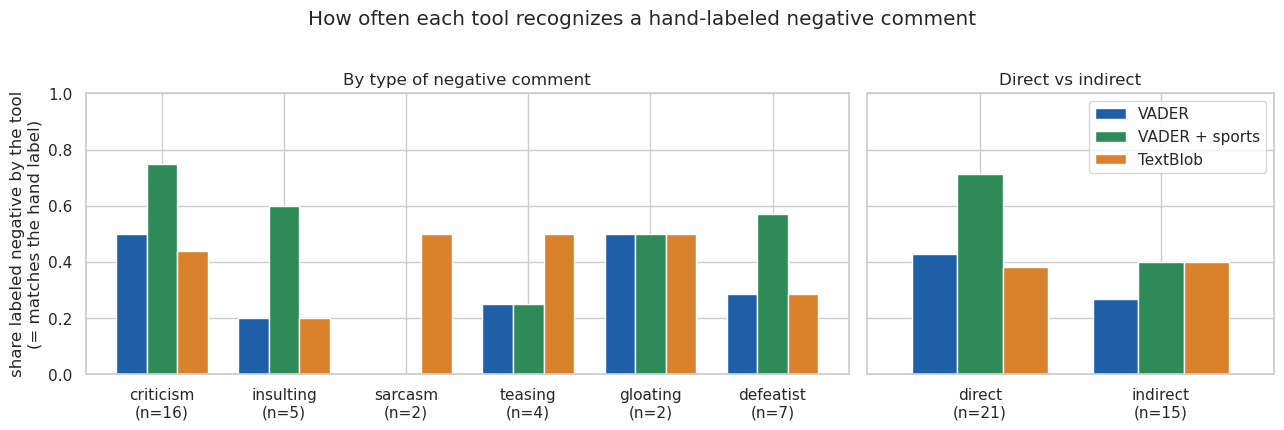

In [13]:
if done.sum() >= 40:
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [3, 1.6]}, sharey=True)
    colors = ["#1f5fa8", "#2e8b57", "#d9822b"]
    for ax, tab, title in [(axes[0], by_type, "By type of negative comment"),
                           (axes[1], by_style.loc[["direct negativity", "indirect negativity"]], "Direct vs indirect")]:
        tab[[f"{t} correct" for t, _ in TOOLS]].plot.bar(ax=ax, color=colors, width=0.75, legend=False)
        ax.set_xticklabels([f"{g.replace(' negativity', '')}\n(n={n})" for g, n in zip(tab.index, tab["comments"])], rotation=0)
        ax.set(ylim=(0, 1), title=title, xlabel=None)
    axes[0].set_ylabel("share labeled negative by the tool\n(= matches the hand label)")
    axes[1].legend([t for t, _ in TOOLS], title=None, loc="upper right")
    fig.suptitle("How often each tool recognizes a hand-labeled negative comment", y=1.02)
    save(fig, "04_failure_patterns.png")

In [14]:
if done.sum() >= 40:
    cols = ["type", "vader_label", "vader_sports_label", "tb_label", "text_body"]
    print("Indirect negative comments and how each tool labeled them:")
    display(neg[neg["style"] == "indirect"].sort_values("type")[cols])
    print("Neutral and positive comments with notes:")
    display(lab[(lab["label"] != "negative") & (lab["note"] != "")][["label", "type"] + cols[1:]])

Indirect negative comments and how each tool labeled them:


,type,vader_label,vader_sports_label,tb_label,text_body
11,defeatist,positive,positive,neutral,Rolltide!! f it at this point 😂
13,defeatist,positive,positive,positive,"I am a Tiger fan but Texas will win, with help from the refs."
22,defeatist,negative,negative,positive,This sucks. One thing that could make this more interesting is only having one ranking at the end of the s...
28,defeatist,negative,negative,positive,Same thing with Bama in 2023 before expansion. UGA was undefeated and Saban was retiring. They had a loss ...
37,defeatist,positive,negative,negative,"I'm a Bama fan, but that poll is pathetic. Do you think the committee gave Bama a 'win' over Georgia when ..."
40,defeatist,positive,negative,positive,"What a complete joke all this is. None on this makes sense and there are no real conferences. Give me 8,..."
45,defeatist,positive,positive,negative,😂😂 and yet we all still watch…. Wait when its a 24 team playoff some will advocate for the entire SEC to m...
39,gloating,negative,negative,negative,Texas derangement syndrome is real as hell. Y’all stay obsessed with those two losses and refuse to give T...
46,gloating,positive,positive,positive,Who would've thought we would keep getting the bama bump even with mediocre coaching lol. Its good to be a...
12,sarcasm,positive,positive,neutral,😂😂😂😂😂 you got it bro


Neutral and positive comments with notes:


,label,type,vader_label,vader_sports_label,tb_label,text_body
0,neutral,gloating,positive,positive,positive,I'm reading these comments sitting cozy in the great state of ALABAMA genuinely LMFAO 😂😂😂\n\nROLL TIDE ROLL!
1,neutral,sarcasm,positive,positive,positive,Lol and cops dont make rules they just enforce them.
2,neutral,factual,neutral,neutral,positive,"No, because Utah and Miami haven't lost. Indiana sure."
15,neutral,factual,neutral,neutral,neutral,"that’s because your looking at power rankings, not the results of the schedule."
27,positive,laughing,negative,negative,neutral,“This is an ass sandwich” - 😂😉
31,neutral,factual,negative,negative,negative,They’re banking on the idea of TN dropping one more game. That’s why they’re keeping TN so low in the rank...


### Labeling rules and decision

The hand labels follow these rules:

1. Label the writer's own feeling, not whether you agree with them and not whether the news is good or bad.
2. Context (the video, the comment being replied to) is used to understand what the words mean, but agreeing or disagreeing with it is stance, not tone, and doesn't decide the label.
3. Calm disagreement or correction is neutral. Criticism of something (a team, the committee, the format) is negative even when calm. Praise is positive.
4. For 😂 and sarcasm, ask what drives the comment: enjoyment (a funny line, playful gloating) is positive; contempt or a putdown is negative.
5. Neutral means no clear feeling. Mixed comments get the feeling that drives them, or neutral with the note "mixed".

**Decision:** VADER + sports words matched the hand labels best, so it is the main score in notebooks 05–08. Standard VADER and TextBlob are reported alongside it. All three tools rate these comments far more positively than the hand labels do, mostly because of sarcasm and laughing emoji, so the absolute positive/negative shares are not reliable. Comparisons (before vs after, creator vs creator) hold up better, because the same bias applies on both sides.

## 5. Expansion-topic flag

Comments are flagged as being about the expansion when they match the terms below. The matches are listed by term so false hits can be spotted.

* **Strong terms** count on their own. A bare "24" isn't enough, because it mostly matches scores ("24-17") and rankings ("top 25"). It has to appear as "24 team(s)".
* **Context terms** ("12 team", "conference championship", "bye") are mostly about *this* season's 12-team playoff. They count only when the same comment also refers to a change or the future ("next year", "2027", "eliminate", "get rid of", "no more", "anymore", "new format"…).

In [15]:
STRONG_TERMS = {
    "24/16 teams": r"\b(?:24|16)[\s-]*teams?\b",
    "expansion": r"\bexpan(?:d|ds|ded|ding|sion)\b",
    "auto bid": r"\bauto(?:matic)?[\s-]*(?:bids?|qualif\w*|berths?)\b",
    "watered down": r"\bwater(?:ed|s|ing)?[\s-]*down\b",
    "on campus": r"\bon[\s-]*campus\b",
    "ESPN deal": r"\bespn\b.{0,40}\b(?:deal|money|rights|contract|billion)\b|\b(?:deal|money|rights|contract|billion)\b.{0,40}\bespn\b",
    "playoff format": r"\b(?:playoff|cfp)\s*(?:format|field|size)\b|\bnfl model\b",
}
CONTEXT_TERMS = {
    "12 teams (+ change)": r"\b12[\s-]*teams?\b",
    "conf championship (+ change)": r"\bconf(?:erence)?\.?\s*(?:championships?|title games?|champ games?)\b|\bccgs?\b",
    "byes (+ change)": r"\bbyes?\b",
}
CHANGE_WORDS = (r"\bnext (?:year|season)\b|\b2027\b|\beliminat\w*|\bget(?:ting)? rid\b|\bno more\b|\banymore\b|"
                r"\bgoing away\b|\bnew (?:format|playoff|system)\b|\bwill be\b|\bfuture\b|\bdone away\b|\bend(?:s|ing)?\b")
EXPANSION_TERMS = {**STRONG_TERMS, **CONTEXT_TERMS}

has_change = df["text_body"].str.contains(CHANGE_WORDS, case=False, regex=True)
term_hits = pd.DataFrame({k: df["text_body"].str.contains(p, case=False, regex=True) for k, p in STRONG_TERMS.items()})
for k, p in CONTEXT_TERMS.items():
    term_hits[k] = df["text_body"].str.contains(p, case=False, regex=True) & has_change
df["is_expansion"] = term_hits.any(axis=1)

print(f"expansion comments: {df['is_expansion'].sum()} ({df['is_expansion'].mean():.1%})")
display(term_hits.sum().sort_values(ascending=False).rename("comments"))
pd.crosstab([df["creator"], df["period"]], df["is_expansion"]).reindex(PERIOD_ORDER, level=1)

expansion comments: 330 (3.5%)

24/16 teams                     200
expansion                        78
conf championship (+ change)     29
auto bid                         21
ESPN deal                        13
byes (+ change)                  10
watered down                      9
12 teams (+ change)               8
playoff format                    6
on campus                         2
Name: comments, dtype: int64

is_expansion             False  True 
creator    period                    
crain_cone before         1139     19
           announcement    373     75
           after           425      2
pate       before         4513     82
           announcement    302     87
           after          2374     65

In [16]:
for term in EXPANSION_TERMS:
    hits = df.loc[term_hits[term], "text_body"]
    if len(hits):
        print(f"--- {term} ({len(hits)}), examples:")
        print(hits.sample(min(3, len(hits)), random_state=0).str[:120].to_string(), "\n")

--- 24/16 teams (200), examples:
2862    This is why we need a 24 team playoff you can’t trust these people. It’s best to atleast have all the team...
7833    You can view 24 teams two ways, that it removes the importance from games, maybe a little but what subs by...
3828    I think it is dumb mainly because all you do is create some of the same main situations today. More top te... 

--- expansion (78), examples:
3831    I wish they'd simply expanded to 16 teams and then never expanded again... would have made for cleaner 8 g...
3452    New rule for short-sighted, Doomsday expansion haters:\nDon't monetize your 24 team playoff bracket predic...
3465    A playoff was the absolute best thing that happened to college football period. A 24 team playoff is gonna... 

--- auto bid (21), examples:
3595    The only way this doesn’t water down the CFP is if you allow each G6 conference champion an auto bid and h...
3810    They really should get rid of conferences and auto bids\nThe super con

In [17]:
pre_video = df["video_published_utc"] < config.ANNOUNCE_UTC
print("Expansion comments on pre-announcement videos, by comment time:")
print(df[pre_video].groupby("after_announce")["is_expansion"].agg(["sum", "mean"])
      .rename(index={False: "before announcement", True: "after announcement"}).round(3).to_string())
print("\nBefore the announcement these reflect the October leak reports, not the official news.")
df[pre_video & ~df["after_announce"] & df["is_expansion"]]["text_body"].str[:120].head(8)

Expansion comments on pre-announcement videos, by comment time:
                     sum   mean
after_announce                 
before announcement   91  0.020
after announcement    10  0.008

Before the announcement these reflect the October leak reports, not the official news.


330     These rankings just remind me of how dumb the 24 team playoff will be. Ohio state and LSU have massively u...
461     Notre Dame’s 2026 playoff resume is fundamentally less competitive than its top-10 peers week in and week ...
530     As a Georgia fan you can have number 1, none of this means anything anyways with three weeks left. People ...
692     Do the rankings matter anymore? CFP poll is all that matters now. And next year with a 24 team playoff the...
947     My case why the Big 12 is undervalued as a conference. I believe the BIG12 is the second best conference T...
995     ugh. I'm tired boss. \n\nI just want the playoffs to start. Esp. even more for next year with 24 teams. \n...
1010    The fact that ESPN has a contract with the SEC, so of course they influence SEC picks for the top spots. I...
1089    Tennessee is a different team then when they played Texas… \nMy problem with the SEC is Ole Miss and LSU a...
Name: text_body, dtype: object

In [18]:
sent = df.groupby("is_expansion")[["vader_compound", "vader_sports_compound", "tb_polarity"]].mean().round(3)
sent.index = ["other comments", "expansion comments"]
sent

,vader_compound,vader_sports_compound,tb_polarity
other comments,0.150,0.133,0.085
expansion comments,0.163,0.149,0.047


## Save the scored table

In [19]:
df.drop(columns=["creator_name"]).to_csv(config.DATA_DIR / "comments_scored.csv", index=False)
print(f"saved comments_scored.csv ({len(df):,} rows)")

saved comments_scored.csv (9,456 rows)
